# Figure 3, Panel E

Lineplots of log2FC accessibility (BAFinh vs veh) between active and primed enhancers after correcting for cRE-strength confounders (H3K4me1 signal, DPF2/BAF signal, accessibility level in control samples) by binning into deciles based on these metrics.

*Output: PanelE_confounder_plots.pdf*

# Setup

In [1]:
# load packages
library(tidyverse)
library(patchwork)
library(RColorBrewer)
library(here)
here::i_am("figures/Figure3/PanelE/PanelE.ipynb")

theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=20)))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         RColorBrewer_1.1-3 patchwork_1.3.0    lubridate_1.9.4   
 [5] forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4        purrr_1.0.2       
 [9] readr_2.1.5        tidyr_1.3.1        tibble_3.2.1       ggplot2_3.5.2     
[13] tidyverse_2.0.0   

loaded via a namespace (an

# Load data

In [2]:
# cRE metadata
row_meta <- read.delim(
    here("inputs", "bed", "ATAC_peaks", "filtered", "consensus_filt_annot.tsv"),
    sep = "\t"
) %>%
    arrange(seqnames, start) %>%
    select(seqnames, start, end, type) %>%
    mutate(
        type = case_when(
            type == "active_enh" ~ "active_enh",
            type == "poised_enh" ~ "primed_enh"
    )
  )

# log2FC values for all cREs
DAR <- read.delim(
    here("inputs", "bed", "ATAC_peaks", "filtered", "consensus_filt_annot_dar.tsv"),
    sep = "\t"
) %>%
    arrange(seqnames, start)

# counts matrix - used for calculating CPM accessibility (in vehicle treated samples)
countmat <- read.delim(
    here("inputs", "countmat", "brm10uM_6h", "consensus_filt_counts.tsv"),
    sep = "\t",
    header = FALSE
) %>%
    arrange(V1, V2)

# bigWigAverageOverBed signal for H3K4me1 and DPF2
h3k4me1 <- read.delim(
    here("inputs", "bigwig", "ENCODE", "GM12878", "H3K4me1.tab"),
    sep = "\t",
    header = FALSE
) %>%
    arrange(V1)

dpf2 <- read.delim(
    here("inputs", "bigwig", "ENCODE", "GM12878", "DPF2.tab"),
    sep = "\t",
    header = FALSE
) %>%
    arrange(V1)

#annotate row metadata with accessibility log2FC, H3K4me1 and DPF2 signal, and control accessibility CPM
row_meta$logFC <- DAR$logFC
row_meta$H3K4me1 <- h3k4me1$V6
row_meta$DPF2 <- dpf2$V6
row_meta$DMSO <- rowMeans(apply(countmat[,5:7], 2, function(x) 1000000*x/sum(x))) #mean CPM per sample

row_meta_enh <- row_meta %>% filter(type %in% c("active_enh", "primed_enh"))

# Statistics
At each decile, distributions of log2FC accessibility for active and primed enhancers compared by Wilcoxon rank-sum tests. After bonferroni multiple test correction, the largest (ie least significant) p-value is reported

In [3]:
#stats
#H3K4me1
pvals_h3k4me1 <- row_meta_enh %>%  mutate(decile=ntile(H3K4me1,10)) %>% select(type,decile,logFC) %>% 
    pivot_longer(!c(type,decile)) %>%
    group_by(decile) %>%
        summarize(
        w_pvalue = wilcox.test(value ~ type)$p.value
  )
pvals_h3k4me1$p.adj <- p.adjust(pvals_h3k4me1$w_pvalue, method="bonferroni")
pvals_h3k4me1

#DPF2
pvals_dpf2 <- row_meta_enh %>%  mutate(decile=ntile(DPF2,10)) %>% select(type,decile,logFC) %>% 
    pivot_longer(!c(type,decile)) %>%
    group_by(decile) %>%
        summarize(
        w_pvalue = wilcox.test(value ~ type)$p.value
  )
pvals_dpf2$p.adj <- p.adjust(pvals_dpf2$w_pvalue, method="bonferroni")
pvals_dpf2
#starting accessibility
pvals_accessibility <- row_meta_enh %>%  mutate(decile=ntile(DMSO,10)) %>% select(type,decile,logFC) %>% 
    pivot_longer(!c(type,decile)) %>%
    group_by(decile) %>%
        summarize(
        w_pvalue = wilcox.test(value ~ type)$p.value
  )
pvals_accessibility$p.adj <- p.adjust(pvals_accessibility$w_pvalue, method="bonferroni")
pvals_accessibility

decile,w_pvalue,p.adj
<int>,<dbl>,<dbl>
1,1.087568e-17,1.087568e-16
2,1.294112e-20,1.294112e-19
3,1.142090e-29,1.142090e-28
4,4.371987e-21,4.371987e-20
5,8.912527e-39,8.912527e-38
6,1.281581e-32,1.281581e-31
7,1.676894e-38,1.676894e-37
8,3.016355e-42,3.016355e-41
9,5.171019e-41,5.171019e-40


decile,w_pvalue,p.adj
<int>,<dbl>,<dbl>
1,5.585988e-21,5.585988e-20
2,1.917814e-35,1.917814e-34
3,2.952288e-24,2.952288e-23
4,1.693051e-27,1.693051e-26
5,2.845985e-35,2.845985e-34
6,1.128491e-38,1.128491e-37
7,7.309352e-54,7.309352e-53
8,1.772429e-52,1.772429e-51
9,1.204653e-78,1.204653e-77


decile,w_pvalue,p.adj
<int>,<dbl>,<dbl>
1,2.133880e-51,2.133880e-50
2,6.417903e-53,6.417903e-52
3,3.092783e-63,3.092783e-62
4,1.929460e-56,1.929460e-55
5,3.178020e-42,3.178020e-41
6,1.965993e-39,1.965993e-38
7,8.172008e-39,8.172008e-38
8,1.942439e-38,1.942439e-37
9,4.376751e-32,4.376751e-31


# Correlation between strength metrics and accessibility change

In [15]:
# H3K4me1 vs logFC
row_meta_enh %>% group_by(type) %>%
    summarize(r=format(cor(logFC,H3K4me1), digits=2))

#DPF2 vs logFC
row_meta_enh %>% group_by(type) %>%
    summarize(r=format(cor(logFC,DPF2), digits=2))

#Accessibility vs logFC
row_meta_enh %>% group_by(type) %>%
    summarize(r=format(cor(logFC,DMSO), digits=2))

type,r
<chr>,<chr>
active_enh,0.032
primed_enh,-0.036


type,r
<chr>,<chr>
active_enh,-0.17
primed_enh,-0.22


type,r
<chr>,<chr>
active_enh,-0.016
primed_enh,-0.13


# Generate plots

In [4]:
H3K4me1_decile_lfc <- row_meta_enh %>%  mutate(decile=ntile(H3K4me1,10)) %>% 
    ggplot(aes(x=decile,y=logFC, color=type)) + 
    geom_hline(yintercept=0, linetype=2) + 
    stat_summary(fun="mean", geom="line", linewidth=1) +
    stat_summary(fun.data=mean_cl_boot, geom="ribbon", fun.args=list(conf.int=.95), aes(fill=type), alpha=.2, color=NA) + 
    scale_x_continuous(breaks=seq(1,10,by=1)) + 
    ylab("log2 fold change in accessibility\nBAFinh vs Vehicle") + xlab("H3K4me1 signal\nbinned by decile") +
    scale_color_manual(values=c("#f2c14e", "#c48b1b")) +
    scale_fill_manual(values=c("#f2c14e", "#c48b1b")) +
    ggtitle(paste0("p < ", format(max(pvals_h3k4me1$p.adj), digits=3))) +
   coord_cartesian(ylim=c(-2.2,0)) + scale_y_continuous(breaks=seq(-2,0,by=1))

DPF2_decile_lfc <- row_meta_enh %>%  mutate(decile=ntile(DPF2,10)) %>% 
    ggplot(aes(x=decile,y=logFC, color=type)) + 
    geom_hline(yintercept=0, linetype=2) + 
    stat_summary(fun="mean", geom="line", linewidth=1) +
    stat_summary(fun.data=mean_cl_boot, geom="ribbon", fun.args=list(conf.int=.95), aes(fill=type), alpha=.2, color=NA) + 
    scale_x_continuous(breaks=seq(1,10,by=1)) + 
    ylab("log2 fold change in accessibility\nBAFinh vs Vehicle") + xlab("DPF2 signal\nbinned by decile") +
    scale_color_manual(values=c("#f2c14e", "#c48b1b")) +
    scale_fill_manual(values=c("#f2c14e", "#c48b1b")) +
    ggtitle(paste0("p < ", format(max(pvals_dpf2$p.adj), digits=3))) +
    coord_cartesian(ylim=c(-2.2,0)) + scale_y_continuous(breaks=seq(-2,0,by=1))
    

accessibility_decile_lfc <- row_meta_enh %>%  mutate(decile=ntile(DMSO,10)) %>% 
    ggplot(aes(x=decile,y=logFC, color=type)) + 
    geom_hline(yintercept=0, linetype=2) + 
    stat_summary(fun="mean", geom="line", linewidth=1) +
    stat_summary(fun.data=mean_cl_boot, geom="ribbon", fun.args=list(conf.int=.95), aes(fill=type), alpha=.2, color=NA) + 
    scale_x_continuous(breaks=seq(1,10,by=1)) + 
    ylab("log2 fold change in accessibility\nBAFinh vs Vehicle") + xlab("control accessibility\nbinned by decile") +
    scale_color_manual(values=c("#f2c14e", "#c48b1b")) +
    scale_fill_manual(values=c("#f2c14e", "#c48b1b")) +
    ggtitle(paste0("p < ", format(max(pvals_accessibility$p.adj), digits=3))) +
    coord_cartesian(ylim=c(-2.2,0)) + scale_y_continuous(breaks=seq(-2,0,by=1))


# Assemble figure panel

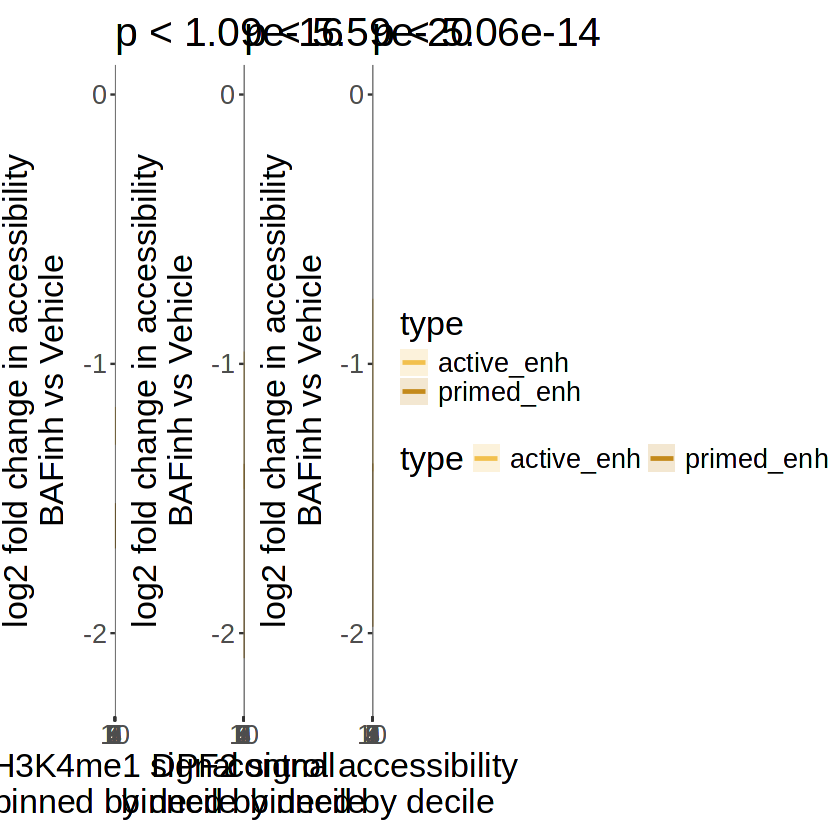

In [6]:
((H3K4me1_decile_lfc) | (DPF2_decile_lfc)  | (accessibility_decile_lfc)) + plot_layout(guides="collect") + theme(legend.position="bottom")
ggsave("PanelE_confounder_plots.pdf", width=12, height=3)